In [1]:
import tensorflow as tf
import tensorflowjs as tfjs
import matplotlib.pyplot as plt
import numpy as np

Training images: 60000 images of size 28x28
Training labels: 60000 labels as integers 0-9
Test images: 10000 images of size 28x28
Test labels: 10000 labels as integers 0-9


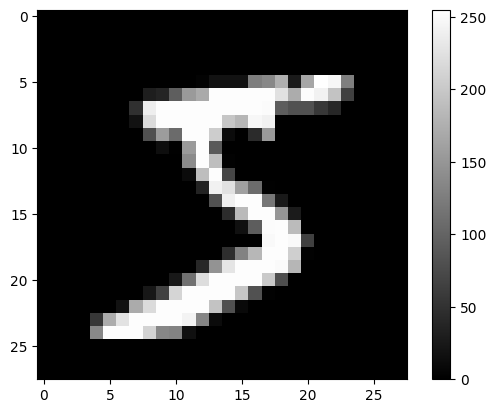

In [2]:
# Load MNIST data
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print(f"Training images: {x_train.shape[0]} images of size {x_train.shape[1]}x{x_train.shape[2]}")
print(f"Training labels: {y_train.shape[0]} labels as integers 0-9")
print(f"Test images: {x_test.shape[0]} images of size {x_test.shape[1]}x{x_test.shape[2]}")
print(f"Test labels: {y_test.shape[0]} labels as integers 0-9")

plt.imshow(x_train[0], cmap='gray')
plt.colorbar()

In [3]:
# Normalize data
x_train = tf.keras.utils.normalize(x_train, axis=1)
x_test = tf.keras.utils.normalize(x_test, axis=1)

In [4]:
# Define the CNN model
model = tf.keras.models.Sequential([
    # First Convolution
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second Convolution
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Fully Connected Layers (Dense)
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [5]:
# Train the model
model.fit(x_train, y_train, epochs=30)

# Evaluate the model
val_loss, val_acc = model.evaluate(x_test, y_test)
print(val_loss, val_acc)

Epoch 1/30
1875/1875 [==============================] - 11s 6ms/step - loss: 0.2692 - accuracy: 0.9183
Epoch 2/30
1875/1875 [==============================] - 11s 6ms/step - loss: 0.1062 - accuracy: 0.9682
Epoch 3/30
1875/1875 [==============================] - 11s 6ms/step - loss: 0.0776 - accuracy: 0.9767
Epoch 4/30
1875/1875 [==============================] - 10s 5ms/step - loss: 0.0648 - accuracy: 0.9803
Epoch 5/30
1875/1875 [==============================] - 10s 5ms/step - loss: 0.0575 - accuracy: 0.9826
Epoch 6/30
1875/1875 [==============================] - 10s 5ms/step - loss: 0.0515 - accuracy: 0.9842
Epoch 7/30
1875/1875 [==============================] - 11s 6ms/step - loss: 0.0465 - accuracy: 0.9846
Epoch 8/30
1875/1875 [==============================] - 10s 6ms/step - loss: 0.0436 - accuracy: 0.9861
Epoch 9/30
1875/1875 [==============================] - 10s 6ms/step - loss: 0.0403 - accuracy: 0.9870
Epoch 10/30
1875/1875 [==============================] - 10s 5ms/step - l

In [6]:
# USE PYTHON 3.8 FOR CORRECT WEBCONVERSION (model.js + group1-shard1of1.bin)

# Save model for TensorFlow.js
tfjs.converters.save_keras_model(model, 'model')

/Users/marcelsayegh/.pyenv/versions/3.8.12/lib/python3.8/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(
